# 02 · Features derivadas y auditoría de fuga

Las features viven en `src/pipeline.py` (`FeatureEngineer`), y este notebook las **importa**; no copia código. Todo el análisis se hace sobre el conjunto de entrenamiento.

| Feature | Definición | Origen |
|---|---|---|
| `meses_desde_ultimo_atraso` | Mes más reciente con `pay_status ≥ 1` (1 = sep … 7 = sin atrasos) | Hallazgo H3 (recencia del atraso) |
| `estado_ultimo_mes` | `pay_status_m1` como categoría (−2…3+) con one-hot | Hallazgo H4 (relación no monótona) |
| `tendencia_mora` | Atrasos de jul–sep menos atrasos de abr–jun | Deterioro reciente |
| `cobertura_ultimo_pago` | `pay_amt_m1 / bill_amt_m2` (pago de sep / saldo de ago), tope 5 | Capacidad de pago |
| `tendencia_utilizacion` | `util_m1 − util_m6` | Endeudamiento creciente |
| Montos en log con signo | `sign(x)·log(1+|x|)` en saldos, pagos y cupo | Hallazgo H2 (colas largas) |

In [1]:
import sys, warnings
sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from src.datos import cargar_obt, dividir, esquema_cv, NO_FEATURES, TARGET
from src.pipeline import FeatureEngineer, construir_pipeline, DERIVADAS
sns.set_theme(style='whitegrid'); IMG = '../docs/img/'
obt, meta = cargar_obt()
X_train, X_test, y_train, y_test = dividir(obt)
F = FeatureEngineer().fit_transform(X_train)     # sin estado: no aprende nada de los datos
F[DERIVADAS].describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
meses_desde_ultimo_atraso,24000.0,NaN,NaN,NaN,5.278042,2.563186,1.0,3.0,7.0,7.0,7.0
tendencia_mora,24000.0,NaN,NaN,NaN,0.198208,0.80236,-3.0,0.0,0.0,0.0,3.0
cobertura_ultimo_pago,21492.0,NaN,NaN,NaN,0.349899,0.477031,0.0,0.042828,0.078344,1.0,5.0
tendencia_utilizacion,24000.0,NaN,NaN,NaN,0.105844,0.299332,-1.6142,-0.029235,0.006874,0.181875,5.3095
estado_ultimo_mes,24000,6,0,11781,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Evidencia de que cada feature aporta

In [2]:
num_der = ['meses_desde_ultimo_atraso','tendencia_mora','cobertura_ultimo_pago','tendencia_utilizacion']
def auc_uni(s, y):
    m = s.notna()
    if m.sum() == 0 or s[m].nunique() < 2: return np.nan
    a = roc_auc_score(y[m], s[m]); return max(a, 1-a)
mi = mutual_info_classif(F[num_der].fillna(F[num_der].median()), y_train, random_state=42)
ev = pd.DataFrame({'AUC_univariada': [auc_uni(F[c], y_train) for c in num_der], 'info_mutua': mi}, index=num_der)
# referencia: las columnas originales más fuertes
for c in ['pay_status_m1','max_delay_6m','avg_utilization_6m']:
    ev.loc[f'(ref) {c}'] = [auc_uni(X_train[c], y_train), mutual_info_classif(X_train[[c]], y_train, random_state=42)[0]]
ev.round(3)

,AUC_univariada,info_mutua
meses_desde_ultimo_atraso,0.722,0.070
tendencia_mora,0.596,0.035
cobertura_ultimo_pago,0.610,0.033
tendencia_utilizacion,0.555,0.012
(ref) pay_status_m1,0.693,0.078
(ref) max_delay_6m,0.719,0.068
(ref) avg_utilization_6m,0.568,0.016


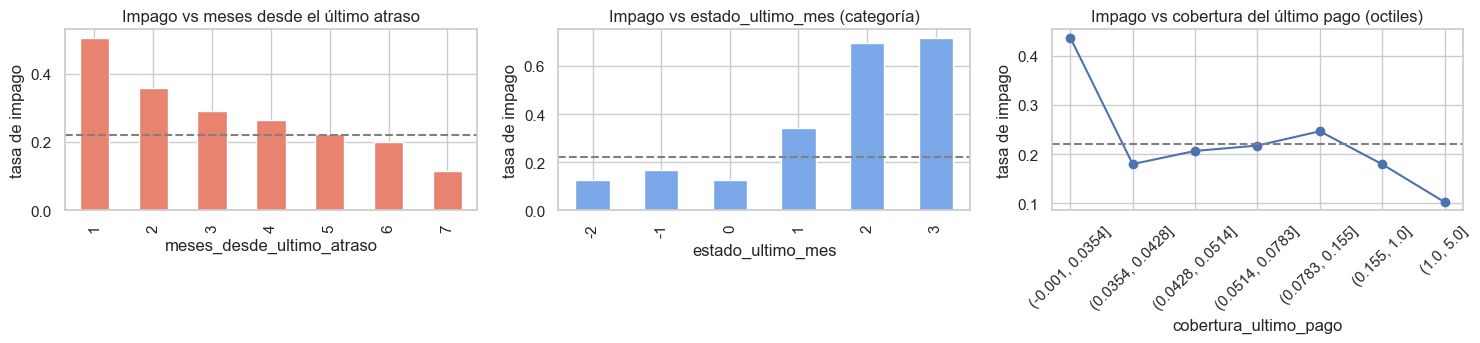

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
F.assign(y=y_train.values).groupby('meses_desde_ultimo_atraso').y.mean().plot.bar(ax=ax[0], color='#e8836f'); ax[0].set_title('Impago vs meses desde el último atraso')
F.assign(y=y_train.values).groupby('estado_ultimo_mes').y.mean().reindex(['-2','-1','0','1','2','3']).plot.bar(ax=ax[1], color='#7aa7e8'); ax[1].set_title('Impago vs estado_ultimo_mes (categoría)')
q = pd.qcut(F.cobertura_ultimo_pago, 8, duplicates='drop')
F.assign(y=y_train.values).groupby(q).y.mean().plot(ax=ax[2], marker='o'); ax[2].set_title('Impago vs cobertura del último pago (octiles)'); ax[2].tick_params(axis='x', rotation=45)
for a in ax: a.axhline(y_train.mean(), ls='--', c='gray'); a.set_ylabel('tasa de impago')
plt.tight_layout(); plt.savefig(IMG+'features_evidencia.png', dpi=150); plt.show()

## 2. Ablación: ¿mejoran el modelo?

Comparo el mismo modelo **con y sin** las features derivadas, usando la misma CV estratificada de 5 pliegues sobre el entrenamiento. Las dos versiones aplican la transformación de montos.

In [4]:
cols = list(X_train.columns); cv = esquema_cv(); filas = []
for nombre, modelo in [('LogisticRegression', LogisticRegression(max_iter=2000)), ('HistGradientBoosting', HistGradientBoostingClassifier(random_state=42))]:
    for der in [False, True]:
        s = cross_val_score(construir_pipeline(modelo, cols, derivadas=der), X_train, y_train, cv=cv, scoring='roc_auc')
        filas.append({'modelo': nombre, 'con_derivadas': der, 'cv_auc_mean': s.mean(), 'cv_auc_std': s.std()})
abl = pd.DataFrame(filas)
abl['mejora_vs_sin'] = abl.groupby('modelo').cv_auc_mean.diff()
abl.to_csv('../docs/ablacion_features.csv', index=False); abl.round(4)

,modelo,con_derivadas,cv_auc_mean,cv_auc_std,mejora_vs_sin
0,LogisticRegression,False,0.7697,0.0078,NaN
1,LogisticRegression,True,0.7806,0.0066,0.0109
2,HistGradientBoosting,False,0.7832,0.0042,NaN
3,HistGradientBoosting,True,0.7842,0.0044,0.0011


## 3. Auditoría de fuga de datos

Una feature solo es válida si existe en el momento de la inferencia, es decir, el 1 de octubre de 2005, antes de conocer el pago de octubre.

In [5]:
auditoria = pd.DataFrame([
 ('meses_desde_ultimo_atraso', 'pay_status_m1..m6', 'abr–sep 2005', 'Sí: estados de cuenta ya cerrados'),
 ('estado_ultimo_mes', 'pay_status_m1', 'sep 2005', 'Sí: último estado cerrado'),
 ('tendencia_mora', 'n_delinquent_months_3m/6m', 'abr–sep 2005', 'Sí'),
 ('cobertura_ultimo_pago', 'pay_amt_m1, bill_amt_m2', 'ago–sep 2005', 'Sí: pago hecho en sep sobre el saldo de ago'),
 ('tendencia_utilizacion', 'util_m1, util_m6', 'abr–sep 2005', 'Sí'),
], columns=['feature','columnas_fuente','ventana_temporal','disponible_en_inferencia'])
auditoria

,feature,columnas_fuente,ventana_temporal,disponible_en_inferencia
0,meses_desde_ultimo_atraso,pay_status_m1..m6,abr–sep 2005,Sí: estados de cuenta ya cerrados
1,estado_ultimo_mes,pay_status_m1,sep 2005,Sí: último estado cerrado
2,tendencia_mora,n_delinquent_months_3m/6m,abr–sep 2005,Sí
3,cobertura_ultimo_pago,"pay_amt_m1, bill_amt_m2",ago–sep 2005,Sí: pago hecho en sep sobre el saldo de ago
4,tendencia_utilizacion,"util_m1, util_m6",abr–sep 2005,Sí


In [6]:
# Pruebas automáticas
feat = FeatureEngineer().fit_transform(X_train).columns
assert TARGET not in feat and not any('label' in c or 'default' in c for c in feat), 'columna derivada del target'
assert 'label_month_key' in NO_FEATURES and 'observation_month_key' in NO_FEATURES
# 1) ninguna feature por sí sola "adivina" el target (una AUC univariada > 0,85 sería sospechosa)
Fn = FeatureEngineer().fit_transform(X_train).select_dtypes('number')
auc_all = Fn.apply(lambda c: auc_uni(c, y_train)).dropna().sort_values(ascending=False)
print('AUC univariada máxima:', auc_all.index[0], round(auc_all.iloc[0], 3)); assert auc_all.iloc[0] < 0.85
# 2) FeatureEngineer es sin estado: transformar una fila sola o dentro del lote da lo mismo
fila = X_train.iloc[[0]]
pd.testing.assert_frame_equal(FeatureEngineer().transform(fila), FeatureEngineer().transform(X_train).iloc[[0]])
# 3) el imputador/escalador se ajusta solo con entrenamiento: sus medianas vienen de X_train
pipe = construir_pipeline(LogisticRegression(max_iter=2000), cols).fit(X_train, y_train)
med = pipe.named_steps['prep'].named_transformers_['num'].named_steps['imputar'].statistics_
cob_idx = list(pipe.named_steps['prep'].transformers_[0][2]).index('cobertura_ultimo_pago')
assert np.isclose(med[cob_idx], F.cobertura_ultimo_pago.median())
print('OK: sin columnas del target, sin features "oráculo", transformación por fila y prep ajustado solo con train')

AUC univariada máxima: n_delinquent_months_6m 0.729


OK: sin columnas del target, sin features "oráculo", transformación por fila y prep ajustado solo con train
